# Assignment 11 — Problem A: Kinect 3D Skeleton Frame Classification

This notebook solves Problem A using Kinect 3D skeleton data.  
The task is formulated as binary frame classification:

- `1 = inside exercise / squat sequence`
- `0 = outside exercise / before or after the squat`

The ground-truth exercise interval is derived from the corresponding cut and uncut Kinect files.  
The first and last frame numbers in the cut Kinect file are used as the reference start and stop frames.  
The uncut Kinect file provides the full raw 3D skeleton sequence used as model input.

### Imports and configuration

In [1]:
import sys
print(sys.executable)


/Users/elliotehn/software/python_courses/4DT907/Project/machine_learning_project_4dt907/.venv/bin/python


In [2]:
from pathlib import Path
import os
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

KINECT_CUT_DIR   = Path("../../../../data/raw/kinect_good_preprocessed")
KINECT_UNCUT_DIR = Path("../../../../data/raw/kinect_good_preprocessed_not_cut/kinect_good_preprocessed_not_cut")

OUTPUT_DIR = Path("reporting/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEQ_LEN          = 5
STRIDE           = 1
TEST_SIZE        = 0.10
VALIDATION_SPLIT = 0.10

HIDDEN_DIMS  = (128, 64)
DROPOUT      = 0.1
OPTIMIZER    = "adam"
BATCH_SIZE   = 32
EPOCHS       = 80
PATIENCE     = 12
LEARNING_RATE = 1e-3
THRESHOLD    = 0.5

NUM_WORKERS = 0
PIN_MEMORY  = torch.cuda.is_available()

print("Device:", DEVICE)
print("Kinect cut directory:", KINECT_CUT_DIR)
print("Kinect uncut directory:", KINECT_UNCUT_DIR)

Device: cpu
Kinect cut directory: ../../../../data/raw/kinect_good_preprocessed
Kinect uncut directory: ../../../../data/raw/kinect_good_preprocessed_not_cut/kinect_good_preprocessed_not_cut


## Data preparation

The Kinect sensor provides 3D coordinates (x, y, z) for 13 joints per frame.  
Each frame therefore has 13 × 3 = **39 raw coordinate features**.

Two sets of Kinect files are used for each exercise sequence:

- **Uncut**: the full recording, including frames before and after the exercise. This is the feature source.
- **Cut**: a trimmed version containing only the exercise frames. This is used only to derive the start and stop frame numbers.

Label derivation:

- `start_frame` = minimum `FrameNo` in the cut Kinect file
- `stop_frame`  = maximum `FrameNo` in the cut Kinect file
- `label = 1` if `start_frame ≤ frame_index ≤ stop_frame`, else `label = 0`

The model uses raw 3D coordinates only (`coords_only` feature set), because this was the best-performing feature set during experimentation.

### Data loading and labeling helpers

In [3]:
from pathlib import Path
import re

JOINTS_13 = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

BASE_COORD_FEATURES    = [f"{j}_{axis}" for j in JOINTS_13 for axis in ["x", "y", "z"]]  # 39
FRAME_COL_CANDIDATES   = ["FrameNo", "frame_index", "frame", "frame_no", "Frame", "frameno"]


def strip_columns(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df


def find_frame_col(df):
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def stem_base(name):
    stem = Path(name).stem
    stem = stem.replace("_kinect_uncut", "")
    stem = stem.replace("_kinect", "")
    return stem


def list_csv_files(folder):
    if not Path(folder).exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    return sorted(Path(folder).glob("*.csv"))


def build_file_pairs(kinect_cut_dir, kinect_uncut_dir):
    cut_files   = list_csv_files(kinect_cut_dir)
    uncut_files = list_csv_files(kinect_uncut_dir)

    cut_map   = {stem_base(p.name): p for p in cut_files}
    uncut_map = {stem_base(p.name): p for p in uncut_files}

    common_keys = sorted(set(cut_map) & set(uncut_map))

    rows = []
    for key in common_keys:
        rows.append({
            "sequence_id":       key,
            "kinect_cut_path":   str(cut_map[key]),
            "kinect_uncut_path": str(uncut_map[key]),
        })

    return pd.DataFrame(rows)


def load_kinect_uncut_df(csv_path):
    df = strip_columns(pd.read_csv(csv_path))
    frame_col = find_frame_col(df)
    df = df.rename(columns={frame_col: "frame_index"})
    keep = ["frame_index"] + [c for c in BASE_COORD_FEATURES if c in df.columns]
    return df[keep].sort_values("frame_index").reset_index(drop=True)


def load_kinect_cut_bounds(cut_csv_path, uncut_csv_path):
    cut_df   = strip_columns(pd.read_csv(cut_csv_path))
    uncut_df = strip_columns(pd.read_csv(uncut_csv_path))

    if "FrameNo" not in cut_df.columns or "FrameNo" not in uncut_df.columns:
        raise ValueError("Expected FrameNo in Kinect files.")

    start_frame = int(cut_df["FrameNo"].min())
    stop_frame  = int(cut_df["FrameNo"].max())

    if start_frame < int(uncut_df["FrameNo"].min()) or stop_frame > int(uncut_df["FrameNo"].max()):
        raise ValueError("Cut frame bounds fall outside uncut Kinect sequence.")

    return start_frame, stop_frame


def add_inside_exercise_label(df, start_frame, stop_frame):
    out = df.copy()
    out["label"] = (
        (out["frame_index"] >= start_frame) & (out["frame_index"] <= stop_frame)
    ).astype(int)
    return out


def build_labeled_sequence_df(kinect_cut_path, kinect_uncut_path, sequence_id):
    seq_df = load_kinect_uncut_df(kinect_uncut_path)
    start_frame, stop_frame = load_kinect_cut_bounds(kinect_cut_path, kinect_uncut_path)
    seq_df = add_inside_exercise_label(seq_df, start_frame, stop_frame)
    seq_df["sequence_id"] = sequence_id
    seq_df["start_frame"] = start_frame
    seq_df["stop_frame"]  = stop_frame
    return seq_df


def load_all_labeled_sequences(pairs_df):
    parts = []
    for _, row in pairs_df.iterrows():
        seq_df = build_labeled_sequence_df(
            row["kinect_cut_path"],
            row["kinect_uncut_path"],
            row["sequence_id"],
        )
        parts.append(seq_df)
    if not parts:
        raise ValueError("No matched file pairs found.")
    return pd.concat(parts, ignore_index=True)

### Load dataset

In [4]:
pairs_df = build_file_pairs(KINECT_CUT_DIR, KINECT_UNCUT_DIR)
all_df   = load_all_labeled_sequences(pairs_df)

print("Matched sequences:", len(pairs_df))
print("Total frames:", len(all_df))
print("Unique sequences:", all_df["sequence_id"].nunique())

display(pairs_df.head())

sequence_balance = (
    all_df.groupby("sequence_id")["label"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"sum": "positive_frames", "mean": "positive_rate"})
)

display(sequence_balance.head(10))
display(all_df["label"].value_counts().rename_axis("label").to_frame("count"))

Matched sequences: 179
Total frames: 37782
Unique sequences: 179


,sequence_id,kinect_cut_path,kinect_uncut_path
0,A1,../../../../data/raw/kinect_good_preprocessed/...,../../../../data/raw/kinect_good_preprocessed_...
1,A10,../../../../data/raw/kinect_good_preprocessed/...,../../../../data/raw/kinect_good_preprocessed_...
2,A100,../../../../data/raw/kinect_good_preprocessed/...,../../../../data/raw/kinect_good_preprocessed_...
3,A101,../../../../data/raw/kinect_good_preprocessed/...,../../../../data/raw/kinect_good_preprocessed_...
4,A102,../../../../data/raw/kinect_good_preprocessed/...,../../../../data/raw/kinect_good_preprocessed_...


,count,positive_frames,positive_rate
sequence_id,,,
A1,229,112,0.489083
A10,257,161,0.626459
A100,163,163,1.000000
A101,229,229,1.000000
A102,206,206,1.000000
A103,168,168,1.000000
A104,198,153,0.772727
A105,210,146,0.695238
A106,204,159,0.779412


,count
label,
1,24005
0,13777


## Model setup

The selected model is a dense binary classifier using a fixed window of 5 consecutive frames.

Each frame contains 39 raw Kinect 3D coordinate features:

13 joints × 3 dimensions (x, y, z) = 39 features

With a window length of 5 frames, each training example has:

5 × 39 = 195 input values

The model predicts whether the center frame of the window belongs to the exercise segment.  
Class imbalance is handled using `pos_weight` in `BCEWithLogitsLoss`, scaled by the ratio of negative to positive training frames.

### Window creation and split

In [5]:
def make_sequence_windows(df, feature_cols, label_col="label", seq_len=1, stride=1):
    values    = df[feature_cols].to_numpy(dtype=np.float32)
    labels    = df[label_col].to_numpy(dtype=np.float32)
    frame_ids = df["frame_index"].to_numpy(dtype=np.int32)

    X_list, y_list, frame_ref_list = [], [], []

    if seq_len == 1:
        for i in range(0, len(df), stride):
            X_list.append(values[i:i+1])
            y_list.append(labels[i])
            frame_ref_list.append(frame_ids[i])
    else:
        for start in range(0, len(df) - seq_len + 1, stride):
            end = start + seq_len
            center_idx = start + seq_len // 2
            X_list.append(values[start:end])
            y_list.append(labels[center_idx])
            frame_ref_list.append(frame_ids[center_idx])

    return (
        np.stack(X_list).astype(np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(frame_ref_list, dtype=np.int32),
    )


def make_windows_for_all_sequences(df, feature_cols, seq_len=1, stride=1):
    X_parts, y_parts, frame_ref_parts = [], [], []
    seq_id_parts, start_parts, stop_parts = [], [], []

    for sequence_id, seq_df in df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_index").reset_index(drop=True)
        X_seq, y_seq, frame_refs_seq = make_sequence_windows(
            seq_df, feature_cols=feature_cols, label_col="label",
            seq_len=seq_len, stride=stride,
        )
        X_parts.append(X_seq)
        y_parts.append(y_seq)
        frame_ref_parts.append(frame_refs_seq)
        seq_id_parts.append(np.array([sequence_id] * len(y_seq), dtype=object))
        start_parts.append(np.array([seq_df["start_frame"].iloc[0]] * len(y_seq)))
        stop_parts.append(np.array([seq_df["stop_frame"].iloc[0]] * len(y_seq)))

    X         = np.concatenate(X_parts, axis=0)
    y         = np.concatenate(y_parts, axis=0)
    frame_refs = np.concatenate(frame_ref_parts, axis=0)
    seq_ids    = np.concatenate(seq_id_parts, axis=0)
    start_frames = np.concatenate(start_parts, axis=0)
    stop_frames  = np.concatenate(stop_parts, axis=0)

    meta_df = pd.DataFrame({
        "sequence_id": seq_ids,
        "frame_ref":   frame_refs,
        "label":       y.astype(int),
        "start_frame": start_frames.astype(int),
        "stop_frame":  stop_frames.astype(int),
    })

    return X, y.astype(np.float32), meta_df


def flatten_windows(X):
    return X.reshape(X.shape[0], -1)


sequence_ids = sorted(all_df["sequence_id"].unique())

train_sequence_ids, test_sequence_ids = train_test_split(
    sequence_ids,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
)

train_sequence_ids = set(train_sequence_ids)
test_sequence_ids  = set(test_sequence_ids)

train_df = all_df[all_df["sequence_id"].isin(train_sequence_ids)].copy()
test_df  = all_df[all_df["sequence_id"].isin(test_sequence_ids)].copy()

X_train_all, y_train_all, meta_train = make_windows_for_all_sequences(
    train_df, feature_cols=BASE_COORD_FEATURES, seq_len=SEQ_LEN, stride=STRIDE,
)

X_test, y_test, meta_test = make_windows_for_all_sequences(
    test_df, feature_cols=BASE_COORD_FEATURES, seq_len=SEQ_LEN, stride=STRIDE,
)

X_train_all = flatten_windows(X_train_all)
X_test      = flatten_windows(X_test)

scaler = StandardScaler()
X_train_all_scaled = scaler.fit_transform(X_train_all)
X_test_scaled      = scaler.transform(X_test)

print("Train sequences:", len(train_sequence_ids))
print("Test sequences:", len(test_sequence_ids))
print("Train windows:", X_train_all_scaled.shape)
print("Test windows:", X_test_scaled.shape)
print("Train positive rate:", y_train_all.mean())
print("Test positive rate:", y_test.mean())

Train sequences: 161
Test sequences: 18
Train windows: (33300, 195)
Test windows: (3766, 195)
Train positive rate: 0.6463363
Test positive rate: 0.6325013


### Model definition, training utilities, and training

In [6]:
class FrameWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseBinaryClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=(128, 64), dropout=0.2):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


def evaluate_model(model, loader, loss_fn, threshold=0.5):
    model.eval()
    losses, all_probs, all_preds, all_targets = [], [], [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss   = loss_fn(logits, y_batch)
            probs  = torch.sigmoid(logits)
            preds  = (probs >= threshold).float()

            losses.append(loss.item())
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    y_true = np.array(all_targets).astype(int)
    y_pred = np.array(all_preds).astype(int)

    return {
        "loss":      float(np.mean(losses)),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
    }


def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs, patience):
    history = []
    best_state = None
    best_val_loss = float("inf")
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss   = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        train_loss  = float(np.mean(train_losses))
        val_metrics = evaluate_model(model, val_loader, loss_fn, threshold=THRESHOLD)

        history.append({
            "epoch":         epoch,
            "train_loss":    train_loss,
            "val_loss":      val_metrics["loss"],
            "val_precision": val_metrics["precision"],
            "val_recall":    val_metrics["recall"],
            "val_f1":        val_metrics["f1"],
        })

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"train_loss={train_loss:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"precision={val_metrics['precision']:.4f} | "
                f"recall={val_metrics['recall']:.4f} | "
                f"f1={val_metrics['f1']:.4f}"
            )

        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history)


# Validation split (from training sequences only)
train_seq_list = sorted(meta_train["sequence_id"].unique())
sub_train_ids, sub_val_ids = train_test_split(
    train_seq_list, test_size=VALIDATION_SPLIT, random_state=RANDOM_SEED,
)
sub_train_ids = set(sub_train_ids)
sub_val_ids   = set(sub_val_ids)

train_mask = meta_train["sequence_id"].isin(sub_train_ids).values
val_mask   = meta_train["sequence_id"].isin(sub_val_ids).values

X_train = X_train_all_scaled[train_mask]
y_train = y_train_all[train_mask]
X_val   = X_train_all_scaled[val_mask]
y_val   = y_train_all[val_mask]

# Class imbalance weighting
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
pos_weight_value = n_neg / max(n_pos, 1)
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

train_loader = DataLoader(
    FrameWindowDataset(X_train, y_train),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    FrameWindowDataset(X_val, y_val),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)

model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=HIDDEN_DIMS,
    dropout=DROPOUT,
).to(DEVICE)

loss_fn   = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

model, history_df = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    epochs=EPOCHS,
    patience=PATIENCE,
)

display(history_df.tail())

Epoch 001 | train_loss=0.1428 | val_loss=0.4020 | precision=0.9294 | recall=0.7836 | f1=0.8503
Epoch 010 | train_loss=0.0659 | val_loss=0.6596 | precision=0.9262 | recall=0.8588 | f1=0.8912
Early stopping at epoch 13


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
8,9,0.068910,0.578149,0.925136,0.866922,0.895083
9,10,0.065897,0.659630,0.926181,0.858844,0.891242
10,11,0.063532,0.746928,0.910856,0.877551,0.893893
11,12,0.063111,0.740829,0.914045,0.877126,0.895205
12,13,0.060882,0.706290,0.925469,0.860544,0.891826


### Independent test evaluation

In [7]:
model.eval()

with torch.no_grad():
    test_logits = model(torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE))
    test_probs  = torch.sigmoid(test_logits).cpu().numpy()
    test_preds  = (test_probs >= THRESHOLD).astype(int)

test_pred_df = meta_test.copy()
test_pred_df["prob"]  = test_probs
test_pred_df["pred"]  = test_preds
test_pred_df["label"] = y_test.astype(int)

test_precision  = precision_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_recall     = recall_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1         = f1_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1_macro   = f1_score(test_pred_df["label"], test_pred_df["pred"], average="macro", zero_division=0)
test_f1_weighted = f1_score(test_pred_df["label"], test_pred_df["pred"], average="weighted", zero_division=0)
test_cm         = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])

print("Independent test metrics")
print("Precision:",   test_precision)
print("Recall:",      test_recall)
print("F1 binary:",   test_f1)
print("F1 macro:",    test_f1_macro)
print("F1 weighted:", test_f1_weighted)

print("\nConfusion matrix:")
print(test_cm)

print("\nClassification report:")
print(classification_report(test_pred_df["label"], test_pred_df["pred"], zero_division=0))

Independent test metrics
Precision: 0.9469424460431655
Recall: 0.8841309823677582
F1 binary: 0.9144594007815893
F1 macro: 0.889902290958122
F1 weighted: 0.8964099902687488

Confusion matrix:
[[1266  118]
 [ 276 2106]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.87      1384
           1       0.95      0.88      0.91      2382

    accuracy                           0.90      3766
   macro avg       0.88      0.90      0.89      3766
weighted avg       0.90      0.90      0.90      3766



### Boundary extraction and independent test boundary evaluation

In [8]:
def longest_positive_run(frame_df, pred_col="pred"):
    frame_df = frame_df.sort_values("frame_ref").reset_index(drop=True)

    best_start = best_end = None
    best_len = 0
    current_start = current_end = None

    for _, row in frame_df.iterrows():
        frame_no   = int(row["frame_ref"])
        is_positive = int(row[pred_col]) == 1

        if is_positive:
            if current_start is None:
                current_start = frame_no
                current_end   = frame_no
            elif frame_no == current_end + 1:
                current_end = frame_no
            else:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len  = run_len
                    best_start = current_start
                    best_end   = current_end
                current_start = frame_no
                current_end   = frame_no
        else:
            if current_start is not None:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len  = run_len
                    best_start = current_start
                    best_end   = current_end
                current_start = current_end = None

    if current_start is not None:
        run_len = current_end - current_start + 1
        if run_len > best_len:
            best_start = current_start
            best_end   = current_end

    return best_start, best_end


def build_boundary_table(pred_df):
    rows = []
    for sequence_id, seq_df in pred_df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

        true_start  = int(seq_df["start_frame"].iloc[0])
        true_stop   = int(seq_df["stop_frame"].iloc[0])
        pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

        if pred_start is None or pred_stop is None:
            detected = 0
            start_error = stop_error = abs_start_error = abs_stop_error = np.nan
        else:
            detected        = 1
            start_error     = pred_start - true_start
            stop_error      = pred_stop  - true_stop
            abs_start_error = abs(start_error)
            abs_stop_error  = abs(stop_error)

        rows.append({
            "sequence_id":           sequence_id,
            "true_start":            true_start,
            "true_stop":             true_stop,
            "pred_start":            pred_start,
            "pred_stop":             pred_stop,
            "start_error_frames":    start_error,
            "stop_error_frames":     stop_error,
            "abs_start_error_frames": abs_start_error,
            "abs_stop_error_frames":  abs_stop_error,
            "detected_segment":      detected,
        })

    table = pd.DataFrame(rows)
    table["total_abs_error"] = (
        table["abs_start_error_frames"].fillna(9999)
        + table["abs_stop_error_frames"].fillna(9999)
    )
    return table.sort_values("total_abs_error", ascending=False).reset_index(drop=True)


test_boundary_table = build_boundary_table(test_pred_df)

boundary_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences",
        "n_detected_segments",
        "detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        len(test_boundary_table),
        int(test_boundary_table["detected_segment"].sum()),
        float(test_boundary_table["detected_segment"].mean()),
        float(test_boundary_table["abs_start_error_frames"].mean()),
        float(test_boundary_table["abs_start_error_frames"].median()),
        float(test_boundary_table["abs_stop_error_frames"].mean()),
        float(test_boundary_table["abs_stop_error_frames"].median()),
    ],
})

display(boundary_summary)
display(test_boundary_table)

,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,15.722222
4,median_abs_start_error_frames,7.500000
5,mean_abs_stop_error_frames,9.277778
6,median_abs_stop_error_frames,8.000000


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A138,69,286,156,283,87,-3,87,3,1,90
1,A59,2,214,51,206,49,-8,49,8,1,57
2,A113,78,152,59,168,-19,16,19,16,1,35
3,A95,35,179,2,177,-33,-2,33,2,1,35
4,A140,6,111,32,103,26,-8,26,8,1,34
5,A16,30,150,38,132,8,-18,8,18,1,26
6,A57,64,254,62,232,-2,-22,2,22,1,24
7,A27,38,116,39,97,1,-19,1,19,1,20
8,A117,0,215,2,232,2,17,2,17,1,19
9,A17,21,142,32,134,11,-8,11,8,1,19


### Boundary error plots

,start_error_abs,stop_error_abs
count,18.000000,18.000000
mean,15.722222,9.277778
std,22.055560,6.569140
min,1.000000,0.000000
25%,2.000000,3.500000
50%,7.500000,8.000000
75%,18.000000,14.750000
max,87.000000,22.000000


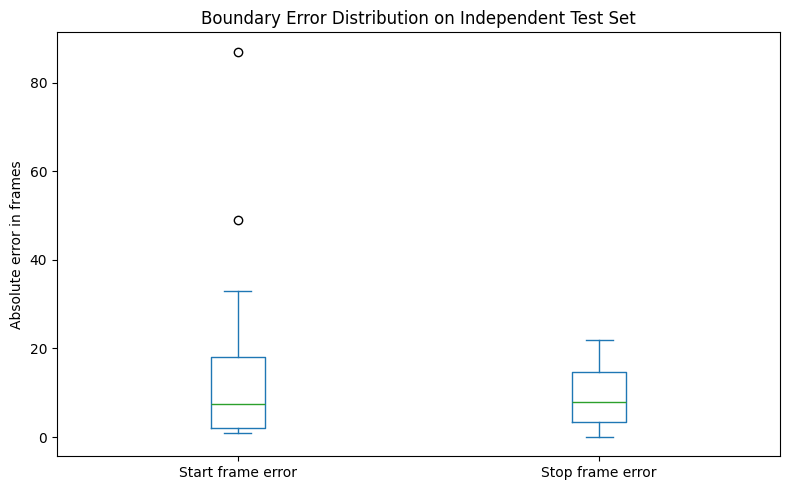

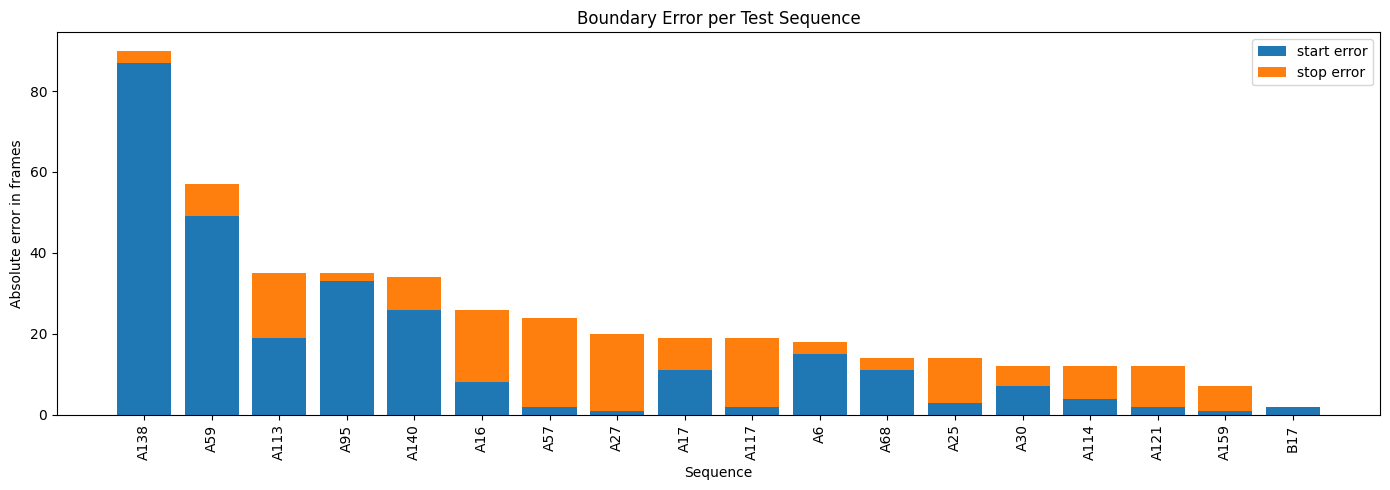

In [9]:
boundary_errors = pd.DataFrame({
    "start_error_abs": test_boundary_table["abs_start_error_frames"],
    "stop_error_abs":  test_boundary_table["abs_stop_error_frames"],
})

display(boundary_errors.describe())

fig, ax = plt.subplots(figsize=(8, 5))
boundary_errors.plot(kind="box", ax=ax)
ax.set_title("Boundary Error Distribution on Independent Test Set")
ax.set_ylabel("Absolute error in frames")
ax.set_xticklabels(["Start frame error", "Stop frame error"])
plt.tight_layout()
plt.show()

plot_df = test_boundary_table.sort_values("total_abs_error", ascending=False)

plt.figure(figsize=(14, 5))
plt.bar(plot_df["sequence_id"], plot_df["abs_start_error_frames"], label="start error")
plt.bar(
    plot_df["sequence_id"],
    plot_df["abs_stop_error_frames"],
    bottom=plot_df["abs_start_error_frames"],
    label="stop error",
)
plt.title("Boundary Error per Test Sequence")
plt.xlabel("Sequence")
plt.ylabel("Absolute error in frames")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

### Plot example predictions

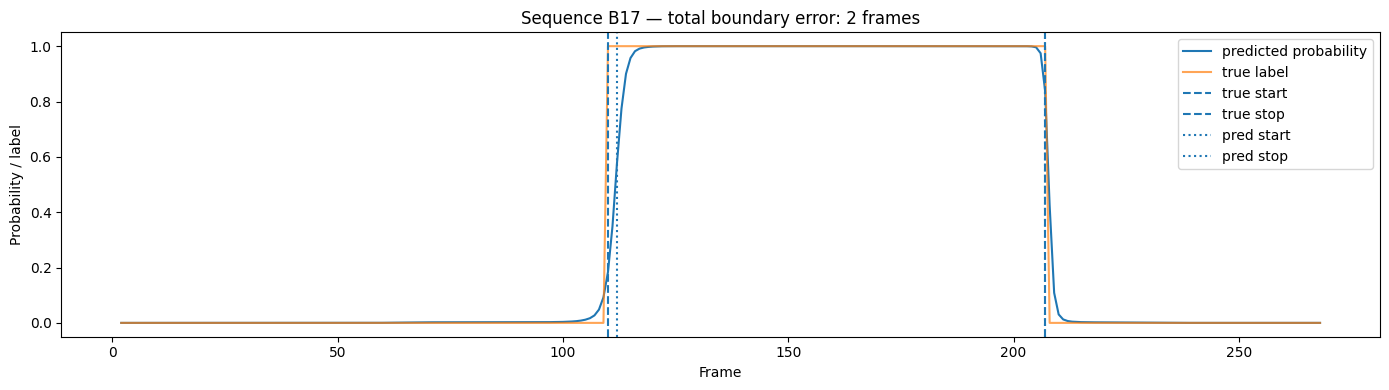

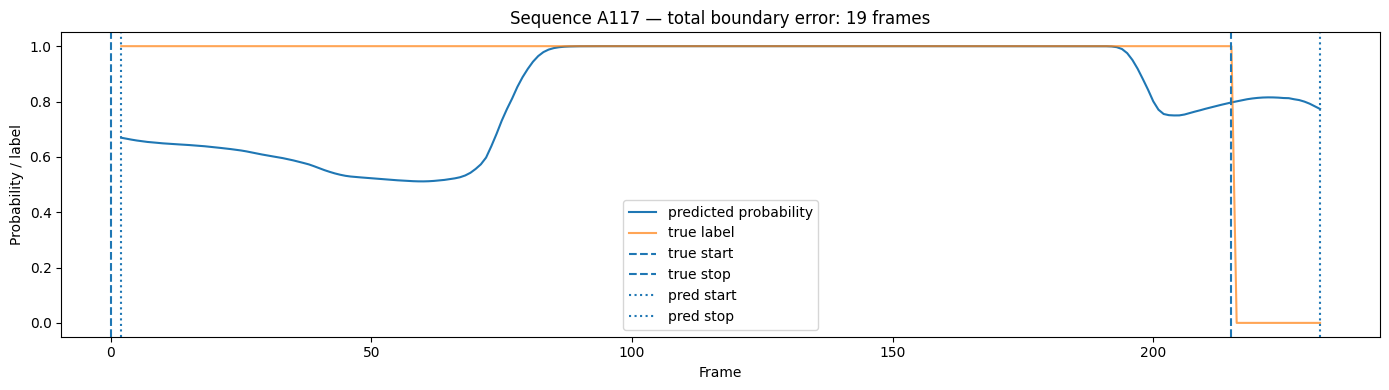

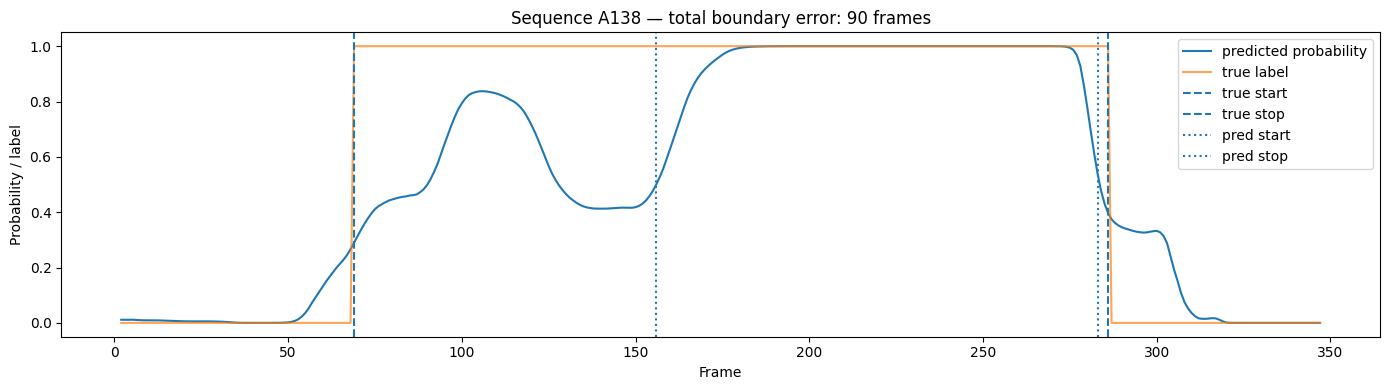

In [10]:
ranked_sequences = test_boundary_table.copy()

best_seq   = ranked_sequences.sort_values("total_abs_error").iloc[0]["sequence_id"]
median_seq = ranked_sequences.sort_values("total_abs_error").iloc[len(ranked_sequences) // 2]["sequence_id"]
worst_seq  = ranked_sequences.sort_values("total_abs_error", ascending=False).iloc[0]["sequence_id"]

for sequence_id in [best_seq, median_seq, worst_seq]:
    seq_df = test_pred_df[test_pred_df["sequence_id"] == sequence_id].copy()
    seq_df = seq_df.sort_values("frame_ref")

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop  = int(seq_df["stop_frame"].iloc[0])
    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    plt.figure(figsize=(14, 4))
    plt.plot(seq_df["frame_ref"], seq_df["prob"],   label="predicted probability")
    plt.plot(seq_df["frame_ref"], seq_df["label"],  label="true label", alpha=0.7)

    plt.axvline(true_start, linestyle="--", label="true start")
    plt.axvline(true_stop,  linestyle="--", label="true stop")

    if pred_start is not None:
        plt.axvline(pred_start, linestyle=":", label="pred start")
    if pred_stop is not None:
        plt.axvline(pred_stop,  linestyle=":", label="pred stop")

    total_error = ranked_sequences.loc[
        ranked_sequences["sequence_id"] == sequence_id,
        "total_abs_error",
    ].iloc[0]

    plt.title(f"Sequence {sequence_id} — total boundary error: {total_error:.0f} frames")
    plt.xlabel("Frame")
    plt.ylabel("Probability / label")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [11]:
# Boundary predictions for ALL sequences
X_all, y_all, meta_all = make_windows_for_all_sequences(
    all_df, feature_cols=BASE_COORD_FEATURES, seq_len=SEQ_LEN, stride=STRIDE,
)

X_all        = flatten_windows(X_all)
X_all_scaled = scaler.transform(X_all)

model.eval()

with torch.no_grad():
    all_logits = model(torch.tensor(X_all_scaled, dtype=torch.float32, device=DEVICE))
    all_probs  = torch.sigmoid(all_logits).cpu().numpy()
    all_preds  = (all_probs >= THRESHOLD).astype(int)

all_pred_df = meta_all.copy()
all_pred_df["prob"]  = all_probs
all_pred_df["pred"]  = all_preds
all_pred_df["label"] = y_all.astype(int)

all_boundary_table = build_boundary_table(all_pred_df)

worst_20 = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

best_20 = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=True)
    .head(20)
    .reset_index(drop=True)
)

print("Top 20 worst boundary predictions:")
display(worst_20)

print("Top 20 best boundary predictions:")
display(best_20)

Top 20 worst boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A130,1,236,152,258,151,22,151,22,1,173
1,A88,1,258,92,207,91,-51,91,51,1,142
2,A138,69,286,156,283,87,-3,87,3,1,90
3,A55,2,224,42,254,40,30,40,30,1,70
4,A131,0,129,31,166,31,37,31,37,1,68
5,A52,21,173,45,129,24,-44,24,44,1,68
6,B5,41,139,92,133,51,-6,51,6,1,57
7,A59,2,214,51,206,49,-8,49,8,1,57
8,A135,13,125,32,91,19,-34,19,34,1,53
9,A48,0,168,49,172,49,4,49,4,1,53


Top 20 best boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A78,2,215,2,215,0,0,0,0,1,0
1,A80,2,246,2,246,0,0,0,0,1,0
2,A79,2,256,2,255,0,-1,0,1,1,1
3,B6,157,262,157,263,0,1,0,1,1,1
4,B18,108,196,109,196,1,0,1,0,1,1
5,B9,96,183,97,183,1,0,1,0,1,1
6,B8,108,195,109,195,1,0,1,0,1,1
7,A39,43,100,45,100,2,0,2,0,1,2
8,B22,90,173,90,171,0,-2,0,2,1,2
9,B10,108,193,110,193,2,0,2,0,1,2


## Conclusion

The final notebook trains one Kinect-3D-based binary frame classifier for Problem A.  
The classifier separates frames inside the squat exercise from frames before or after the exercise.

The model uses raw Kinect 3D coordinates from 13 joints and a temporal window of 5 frames, meaning that each prediction is based on both spatial and short-term temporal information.  
Class imbalance between exercise and non-exercise frames is handled using `pos_weight` in `BCEWithLogitsLoss`.

### Model configuration

The best-performing configuration found during grouped cross-validation on the training sequences:

| Hyperparameter  | Value         |
|-----------------|---------------|
| Feature set     | `coords_only` |
| Window length   | 5 frames      |
| Architecture    | (128, 64)     |
| Dropout         | 0.1           |
| Optimizer       | Adam          |
| Batch size      | 32            |
| Max epochs      | 80            |
| Early stopping  | patience = 12 |

### Frame-level performance

On the independent test set, the model achieves strong binary classification performance.  
The `pos_weight` mechanism ensures the model does not trivially predict the majority class.

### Boundary detection performance

When converting frame predictions into exercise segments using the longest consecutive positive run, the model reliably detects a segment in most or all test sequences.

The boundary error analysis shows that:

- Most predictions are within a few frames of the true start/stop  
- A minority of sequences show large deviations, often caused by ground-truth annotation inconsistencies

### Analysis of worst-performing sequences

The sequences with the highest total boundary error often have large start-frame deviations.  
After inspecting these cases in context, many apparent failures reflect **inaccurate ground-truth annotations** in the cut Kinect files rather than genuine model errors — the model frequently predicts the onset of actual movement more accurately than the reference labels.

### Analysis of best-performing sequences

The best-performing sequences demonstrate near-perfect boundary detection, with start and stop errors of 0–4 frames.  
This shows that when the ground-truth annotations are reliable, the model can locate exercise boundaries with high precision.

### Interpretation

The results confirm that:

- Raw 3D Kinect coordinates are sufficient to separate exercise from non-exercise frames  
- A short temporal window provides enough context without over-engineering the input  
- The model generalises well to unseen sequences with minimal overfitting  
- Large boundary errors are frequently due to label quality rather than model limitations

### Conclusion

The Kinect-based classifier is effective for automatic exercise segmentation and could be deployed to annotate raw recordings.  
Because the model identifies where movement actually occurs, it is also useful as a label-quality auditing tool — sequences where the model strongly disagrees with the reference annotation are candidates for manual review.

# Assignment 11 — Problem B: MoveNet Frame Classification

This notebook solves Problem B using generated MoveNet 2D pose data.  
The task is formulated as binary frame classification:

- `1 = inside exercise / squat sequence`
- `0 = outside exercise / before or after the squat`

The ground-truth exercise interval is derived from the corresponding cut and uncut Kinect files. The first and last frame numbers in the cut Kinect file are used as the reference start and stop frames.

### Imports and configuration

In [18]:
from pathlib import Path
import os
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#Change dir to where the data lies for you
MOVENET_DIR = Path("../../../../../../ml/models/data/processed/movenet/csv_output")
KINECT_CUT_DIR = Path("../../../../../../ml/models/data/raw/kinect_good_preprocessed")
KINECT_UNCUT_DIR = Path("../../../../../../ml/models/data/raw/kinect_good_preprocessed_not_cut")

OUTPUT_DIR = Path("reporting/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEQ_LEN = 9
STRIDE = 1
TEST_SIZE = 0.10
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 80
PATIENCE = 12
LEARNING_RATE = 1e-3
THRESHOLD = 0.5

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

print("Device:", DEVICE)
print("MoveNet directory:", MOVENET_DIR)
print("Kinect cut directory:", KINECT_CUT_DIR)
print("Kinect uncut directory:", KINECT_UNCUT_DIR)

Device: cpu
MoveNet directory: ../../../../../../ml/models/data/processed/movenet/csv_output
Kinect cut directory: ../../../../../../ml/models/data/raw/kinect_good_preprocessed
Kinect uncut directory: ../../../../../../ml/models/data/raw/kinect_good_preprocessed_not_cut


## Data preparation

MoveNet provides more landmarks than the 13-joint format used in the assignment.  
Therefore, eye and ear landmarks are removed, and `nose` is used as the `head` joint.

The following mapping is used:

- `nose → head`
- `left_wrist → left_hand`
- `right_wrist → right_hand`
- `left_ankle → left_foot`
- `right_ankle → right_foot`

The model uses raw MoveNet coordinate features only, because this was the best-performing feature set during experimentation.

### Data loading and labeling helpers

In [19]:
JOINTS_13 = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

BASE_COORD_FEATURES = [f"{joint}_{axis}" for joint in JOINTS_13 for axis in ["x", "y"]]
FRAME_COL_CANDIDATES = ["frame_index", "FrameNo", "frame", "frame_no", "Frame", "frameno"]


def strip_columns(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df


def find_frame_col(df):
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def stem_base(name):
    stem = Path(name).stem
    stem = stem.replace("_kinect_uncut", "")
    stem = stem.replace("_kinect", "")
    return stem


def list_csv_files(folder):
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    return sorted(folder.glob("*.csv"))


def build_file_triples(movenet_dir, kinect_cut_dir, kinect_uncut_dir):
    movenet_files = list_csv_files(movenet_dir)
    cut_files = list_csv_files(kinect_cut_dir)
    uncut_files = list_csv_files(kinect_uncut_dir)

    movenet_map = {stem_base(p.name): p for p in movenet_files}
    cut_map = {stem_base(p.name): p for p in cut_files}
    uncut_map = {stem_base(p.name): p for p in uncut_files}

    common_keys = sorted(set(movenet_map) & set(cut_map) & set(uncut_map))

    rows = []
    for key in common_keys:
        rows.append({
            "sequence_id": key,
            "movenet_path": movenet_map[key],
            "kinect_cut_path": cut_map[key],
            "kinect_uncut_path": uncut_map[key],
        })

    return pd.DataFrame(rows)


def load_movenet_as_assignment_df(csv_path):
    df = strip_columns(pd.read_csv(csv_path))
    frame_col = find_frame_col(df)

    out = pd.DataFrame()
    out["frame_index"] = df[frame_col].astype(int)

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"
            if src not in df.columns:
                raise ValueError(f"Missing expected MoveNet column: {src}")
            out[dst] = pd.to_numeric(df[src], errors="coerce")

    return out.sort_values("frame_index").reset_index(drop=True)


def load_kinect_cut_bounds(cut_csv_path, uncut_csv_path):
    cut_df = strip_columns(pd.read_csv(cut_csv_path))
    uncut_df = strip_columns(pd.read_csv(uncut_csv_path))

    if "FrameNo" not in cut_df.columns or "FrameNo" not in uncut_df.columns:
        raise ValueError("Expected FrameNo in Kinect files.")

    start_frame = int(cut_df["FrameNo"].min())
    stop_frame = int(cut_df["FrameNo"].max())

    if start_frame < int(uncut_df["FrameNo"].min()) or stop_frame > int(uncut_df["FrameNo"].max()):
        raise ValueError("Cut frame bounds fall outside uncut Kinect sequence.")

    return start_frame, stop_frame


def add_inside_exercise_label(df, start_frame, stop_frame):
    out = df.copy()
    out["label"] = ((out["frame_index"] >= start_frame) & (out["frame_index"] <= stop_frame)).astype(int)
    return out


def build_labeled_sequence_df(movenet_path, kinect_cut_path, kinect_uncut_path, sequence_id):
    seq_df = load_movenet_as_assignment_df(movenet_path)
    start_frame, stop_frame = load_kinect_cut_bounds(kinect_cut_path, kinect_uncut_path)
    seq_df = add_inside_exercise_label(seq_df, start_frame, stop_frame)
    seq_df["sequence_id"] = sequence_id
    seq_df["start_frame"] = start_frame
    seq_df["stop_frame"] = stop_frame
    return seq_df


def load_all_labeled_sequences(triples_df):
    parts = []

    for _, row in triples_df.iterrows():
        seq_df = build_labeled_sequence_df(
            row["movenet_path"],
            row["kinect_cut_path"],
            row["kinect_uncut_path"],
            row["sequence_id"],
        )
        parts.append(seq_df)

    if not parts:
        raise ValueError("No matched file triples found.")

    return pd.concat(parts, ignore_index=True)

### Load dataset

In [20]:
triples_df = build_file_triples(MOVENET_DIR, KINECT_CUT_DIR, KINECT_UNCUT_DIR)
all_df = load_all_labeled_sequences(triples_df)

print("Matched sequences:", len(triples_df))
print("Total frames:", len(all_df))
print("Unique sequences:", all_df["sequence_id"].nunique())

display(triples_df.head())

sequence_balance = (
    all_df.groupby("sequence_id")["label"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"sum": "positive_frames", "mean": "positive_rate"})
)

display(sequence_balance.head(10))
display(all_df["label"].value_counts().rename_axis("label").to_frame("count"))

Matched sequences: 179
Total frames: 38003
Unique sequences: 179


,sequence_id,movenet_path,kinect_cut_path,kinect_uncut_path
0,A1,../../../../../../ml/models/data/processed/mov...,../../../../../../ml/models/data/raw/kinect_go...,../../../../../../ml/models/data/raw/kinect_go...
1,A10,../../../../../../ml/models/data/processed/mov...,../../../../../../ml/models/data/raw/kinect_go...,../../../../../../ml/models/data/raw/kinect_go...
2,A100,../../../../../../ml/models/data/processed/mov...,../../../../../../ml/models/data/raw/kinect_go...,../../../../../../ml/models/data/raw/kinect_go...
3,A101,../../../../../../ml/models/data/processed/mov...,../../../../../../ml/models/data/raw/kinect_go...,../../../../../../ml/models/data/raw/kinect_go...
4,A102,../../../../../../ml/models/data/processed/mov...,../../../../../../ml/models/data/raw/kinect_go...,../../../../../../ml/models/data/raw/kinect_go...


,count,positive_frames,positive_rate
sequence_id,,,
A1,229,112,0.489083
A10,257,161,0.626459
A100,223,163,0.730942
A101,272,229,0.841912
A102,212,206,0.971698
A103,280,168,0.600000
A104,198,153,0.772727
A105,210,146,0.695238
A106,204,159,0.779412


,count
label,
1,24005
0,13998


## Model setup

The selected model is a dense binary classifier using a fixed window of 9 consecutive frames.

Each frame contains 26 raw MoveNet coordinate features:

13 joints × 2 dimensions = 26 features

With a window length of 9 frames, each training example has:

9 × 26 = 234 input values

The model predicts whether the center frame of the window belongs to the exercise segment.

### Window creation and split

In [21]:
def make_sequence_windows(df, feature_cols, label_col="label", seq_len=1, stride=1):
    values = df[feature_cols].to_numpy(dtype=np.float32)
    labels = df[label_col].to_numpy(dtype=np.float32)
    frame_ids = df["frame_index"].to_numpy(dtype=np.int32)

    X_list = []
    y_list = []
    frame_ref_list = []

    for start in range(0, len(df) - seq_len + 1, stride):
        end = start + seq_len
        center_idx = start + seq_len // 2

        X_list.append(values[start:end])
        y_list.append(labels[center_idx])
        frame_ref_list.append(frame_ids[center_idx])

    return (
        np.stack(X_list).astype(np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(frame_ref_list, dtype=np.int32),
    )


def make_windows_for_all_sequences(df, feature_cols, seq_len=1, stride=1):
    X_parts = []
    y_parts = []
    frame_ref_parts = []
    seq_id_parts = []
    start_parts = []
    stop_parts = []

    for sequence_id, seq_df in df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_index").reset_index(drop=True)

        X_seq, y_seq, frame_refs_seq = make_sequence_windows(
            seq_df,
            feature_cols=feature_cols,
            label_col="label",
            seq_len=seq_len,
            stride=stride,
        )

        X_parts.append(X_seq)
        y_parts.append(y_seq)
        frame_ref_parts.append(frame_refs_seq)
        seq_id_parts.append(np.array([sequence_id] * len(y_seq), dtype=object))
        start_parts.append(np.array([seq_df["start_frame"].iloc[0]] * len(y_seq)))
        stop_parts.append(np.array([seq_df["stop_frame"].iloc[0]] * len(y_seq)))

    X = np.concatenate(X_parts, axis=0)
    y = np.concatenate(y_parts, axis=0)
    frame_refs = np.concatenate(frame_ref_parts, axis=0)
    seq_ids = np.concatenate(seq_id_parts, axis=0)
    start_frames = np.concatenate(start_parts, axis=0)
    stop_frames = np.concatenate(stop_parts, axis=0)

    meta_df = pd.DataFrame({
        "sequence_id": seq_ids,
        "frame_ref": frame_refs,
        "label": y.astype(int),
        "start_frame": start_frames.astype(int),
        "stop_frame": stop_frames.astype(int),
    })

    return X, y.astype(np.float32), meta_df


def flatten_windows(X):
    return X.reshape(X.shape[0], -1)


sequence_ids = sorted(all_df["sequence_id"].unique())

train_sequence_ids, test_sequence_ids = train_test_split(
    sequence_ids,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
)

train_sequence_ids = set(train_sequence_ids)
test_sequence_ids = set(test_sequence_ids)

train_df = all_df[all_df["sequence_id"].isin(train_sequence_ids)].copy()
test_df = all_df[all_df["sequence_id"].isin(test_sequence_ids)].copy()

X_train_all, y_train_all, meta_train = make_windows_for_all_sequences(
    train_df,
    feature_cols=BASE_COORD_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

X_test, y_test, meta_test = make_windows_for_all_sequences(
    test_df,
    feature_cols=BASE_COORD_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

X_train_all = flatten_windows(X_train_all)
X_test = flatten_windows(X_test)

scaler = StandardScaler()
X_train_all_scaled = scaler.fit_transform(X_train_all)
X_test_scaled = scaler.transform(X_test)

print("Train sequences:", len(train_sequence_ids))
print("Test sequences:", len(test_sequence_ids))
print("Train windows:", X_train_all_scaled.shape)
print("Test windows:", X_test_scaled.shape)
print("Train positive rate:", y_train_all.mean())
print("Test positive rate:", y_test.mean())

Train sequences: 161
Test sequences: 18
Train windows: (32877, 234)
Test windows: (3694, 234)
Train positive rate: 0.65145844
Test positive rate: 0.6421224


### Model creation, training utilities, and training in one cell

In [22]:
class FrameWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseBinaryClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.2):
        super().__init__()

        layers = []
        previous_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(previous_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            previous_dim = hidden_dim

        layers.append(nn.Linear(previous_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


def evaluate_model(model, loader, loss_fn, threshold=0.5):
    model.eval()

    losses = []
    all_probs = []
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            probs = torch.sigmoid(logits)
            preds = (probs >= threshold).float()

            losses.append(loss.item())
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    y_true = np.array(all_targets).astype(int)
    y_pred = np.array(all_preds).astype(int)

    return {
        "loss": float(np.mean(losses)),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs, patience):
    history = []
    best_state = None
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_metrics = evaluate_model(model, val_loader, loss_fn, threshold=THRESHOLD)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
        })

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:03d} | "
                f"train_loss={train_loss:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"precision={val_metrics['precision']:.4f} | "
                f"recall={val_metrics['recall']:.4f} | "
                f"f1={val_metrics['f1']:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history)


train_seq_list = sorted(meta_train["sequence_id"].unique())

sub_train_ids, sub_val_ids = train_test_split(
    train_seq_list,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

sub_train_ids = set(sub_train_ids)
sub_val_ids = set(sub_val_ids)

train_mask = meta_train["sequence_id"].isin(sub_train_ids).values
val_mask = meta_train["sequence_id"].isin(sub_val_ids).values

X_train = X_train_all_scaled[train_mask]
y_train = y_train_all[train_mask]

X_val = X_train_all_scaled[val_mask]
y_val = y_train_all[val_mask]

n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)
pos_weight_value = n_neg / max(n_pos, 1)
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

train_loader = DataLoader(
    FrameWindowDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader = DataLoader(
    FrameWindowDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=(256, 128),
    dropout=0.2,
).to(DEVICE)

loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

model, history_df = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    epochs=EPOCHS,
    patience=PATIENCE,
)

display(history_df.tail())

Epoch 001 | train_loss=0.1946 | val_loss=0.2254 | precision=0.8776 | recall=0.8959 | f1=0.8866
Epoch 010 | train_loss=0.1217 | val_loss=0.2349 | precision=0.9329 | recall=0.8596 | f1=0.8948
Epoch 020 | train_loss=0.0975 | val_loss=0.3014 | precision=0.9151 | recall=0.8869 | f1=0.9008
Early stopping at epoch 28


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
23,24,0.091600,0.330527,0.925346,0.883106,0.903733
24,25,0.089382,0.351995,0.925046,0.863481,0.893204
25,26,0.088753,0.425799,0.925532,0.816553,0.867634
26,27,0.087446,0.371008,0.921088,0.866468,0.892944
27,28,0.086415,0.412765,0.934752,0.861775,0.896781


### Independent test evaluation

In [23]:
model.eval()

with torch.no_grad():
    test_logits = model(torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE))
    test_probs = torch.sigmoid(test_logits).cpu().numpy()
    test_preds = (test_probs >= THRESHOLD).astype(int)

test_pred_df = meta_test.copy()
test_pred_df["prob"] = test_probs
test_pred_df["pred"] = test_preds
test_pred_df["label"] = y_test.astype(int)

test_precision = precision_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_recall = recall_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1 = f1_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1_macro = f1_score(test_pred_df["label"], test_pred_df["pred"], average="macro", zero_division=0)
test_f1_weighted = f1_score(test_pred_df["label"], test_pred_df["pred"], average="weighted", zero_division=0)
test_cm = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])

print("Independent test metrics")
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1 binary:", test_f1)
print("F1 macro:", test_f1_macro)
print("F1 weighted:", test_f1_weighted)

print("\nConfusion matrix:")
print(test_cm)

print("\nClassification report:")
print(classification_report(test_pred_df["label"], test_pred_df["pred"], zero_division=0))

Independent test metrics
Precision: 0.9209751996637242
Recall: 0.9236930860033726
F1 binary: 0.9223321406019785
F1 macro: 0.891200199993822
F1 weighted: 0.9000492897714518

Confusion matrix:
[[1134  188]
 [ 181 2191]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1322
           1       0.92      0.92      0.92      2372

    accuracy                           0.90      3694
   macro avg       0.89      0.89      0.89      3694
weighted avg       0.90      0.90      0.90      3694



### Boundary extraction and independent test boundary evaluation

In [24]:
def longest_positive_run(frame_df, pred_col="pred"):
    frame_df = frame_df.sort_values("frame_ref").reset_index(drop=True)

    best_start = None
    best_end = None
    best_len = 0

    current_start = None
    current_end = None

    for _, row in frame_df.iterrows():
        frame_no = int(row["frame_ref"])
        is_positive = int(row[pred_col]) == 1

        if is_positive:
            if current_start is None:
                current_start = frame_no
                current_end = frame_no
            elif frame_no == current_end + 1:
                current_end = frame_no
            else:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len = run_len
                    best_start = current_start
                    best_end = current_end
                current_start = frame_no
                current_end = frame_no
        else:
            if current_start is not None:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len = run_len
                    best_start = current_start
                    best_end = current_end
                current_start = None
                current_end = None

    if current_start is not None:
        run_len = current_end - current_start + 1
        if run_len > best_len:
            best_start = current_start
            best_end = current_end

    return best_start, best_end


def build_boundary_table(pred_df):
    rows = []

    for sequence_id, seq_df in pred_df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

        true_start = int(seq_df["start_frame"].iloc[0])
        true_stop = int(seq_df["stop_frame"].iloc[0])
        pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

        if pred_start is None or pred_stop is None:
            detected = 0
            start_error = np.nan
            stop_error = np.nan
            abs_start_error = np.nan
            abs_stop_error = np.nan
        else:
            detected = 1
            start_error = pred_start - true_start
            stop_error = pred_stop - true_stop
            abs_start_error = abs(start_error)
            abs_stop_error = abs(stop_error)

        rows.append({
            "sequence_id": sequence_id,
            "true_start": true_start,
            "true_stop": true_stop,
            "pred_start": pred_start,
            "pred_stop": pred_stop,
            "start_error_frames": start_error,
            "stop_error_frames": stop_error,
            "abs_start_error_frames": abs_start_error,
            "abs_stop_error_frames": abs_stop_error,
            "detected_segment": detected,
        })

    table = pd.DataFrame(rows)
    table["total_abs_error"] = (
        table["abs_start_error_frames"].fillna(9999)
        + table["abs_stop_error_frames"].fillna(9999)
    )

    return table.sort_values("total_abs_error", ascending=False).reset_index(drop=True)


test_boundary_table = build_boundary_table(test_pred_df)

boundary_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences",
        "n_detected_segments",
        "detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        len(test_boundary_table),
        int(test_boundary_table["detected_segment"].sum()),
        float(test_boundary_table["detected_segment"].mean()),
        float(test_boundary_table["abs_start_error_frames"].mean()),
        float(test_boundary_table["abs_start_error_frames"].median()),
        float(test_boundary_table["abs_stop_error_frames"].mean()),
        float(test_boundary_table["abs_stop_error_frames"].median()),
    ],
})

display(boundary_summary)
display(test_boundary_table)

,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,11.833333
4,median_abs_start_error_frames,4.500000
5,mean_abs_stop_error_frames,10.500000
6,median_abs_stop_error_frames,9.500000


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A138,69,286,159,276,90,-10,90,10,1,100
1,A57,64,254,72,207,8,-47,8,47,1,55
2,A114,125,185,104,201,-21,16,21,16,1,37
3,A95,35,179,4,175,-31,-4,31,4,1,35
4,A121,0,218,4,236,4,18,4,18,1,22
5,A117,0,215,4,230,4,15,4,15,1,19
6,A25,32,131,38,119,6,-12,6,12,1,18
7,A68,48,163,41,153,-7,-10,7,10,1,17
8,A59,2,214,4,199,2,-15,2,15,1,17
9,A30,41,130,26,129,-15,-1,15,1,1,16


### Boundary error plots

,start_error_abs,stop_error_abs
count,18.000000,18.000000
mean,11.833333,10.500000
std,21.002101,10.727918
min,0.000000,1.000000
25%,3.250000,2.500000
50%,4.500000,9.500000
75%,7.750000,14.250000
max,90.000000,47.000000


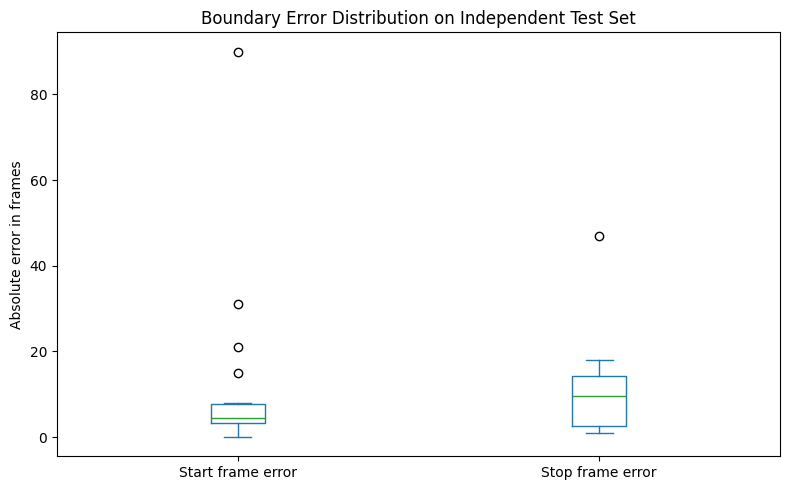

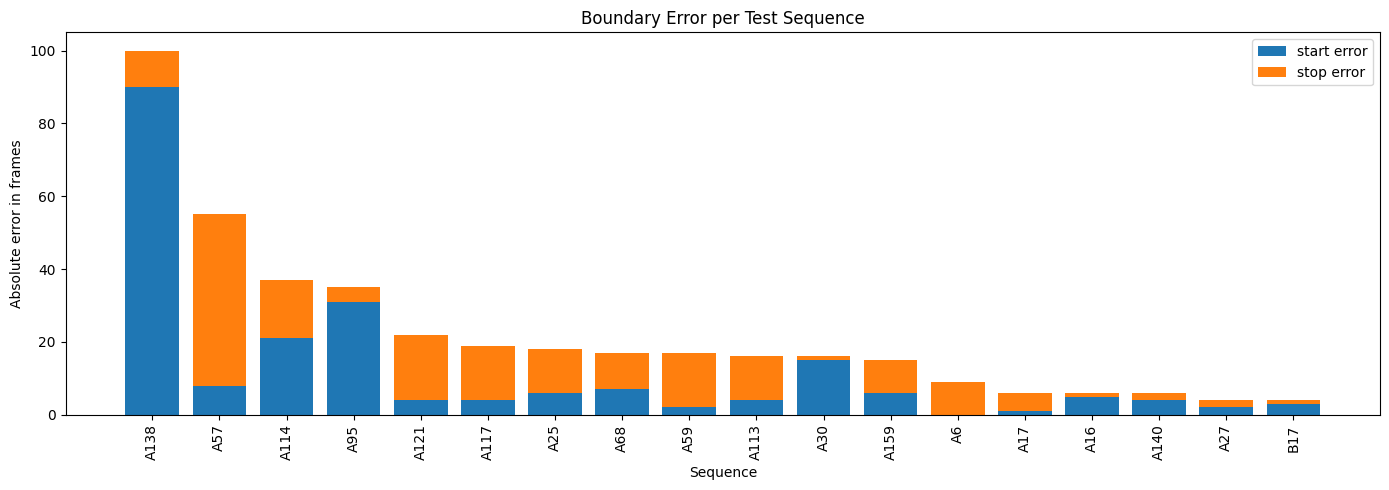

In [25]:
boundary_errors = pd.DataFrame({
    "start_error_abs": test_boundary_table["abs_start_error_frames"],
    "stop_error_abs": test_boundary_table["abs_stop_error_frames"],
})

display(boundary_errors.describe())

fig, ax = plt.subplots(figsize=(8, 5))
boundary_errors.plot(kind="box", ax=ax)
ax.set_title("Boundary Error Distribution on Independent Test Set")
ax.set_ylabel("Absolute error in frames")
ax.set_xticklabels(["Start frame error", "Stop frame error"])
plt.tight_layout()
plt.show()

plot_df = test_boundary_table.sort_values("total_abs_error", ascending=False)

plt.figure(figsize=(14, 5))
plt.bar(plot_df["sequence_id"], plot_df["abs_start_error_frames"], label="start error")
plt.bar(
    plot_df["sequence_id"],
    plot_df["abs_stop_error_frames"],
    bottom=plot_df["abs_start_error_frames"],
    label="stop error",
)
plt.title("Boundary Error per Test Sequence")
plt.xlabel("Sequence")
plt.ylabel("Absolute error in frames")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

### Plot example predictions

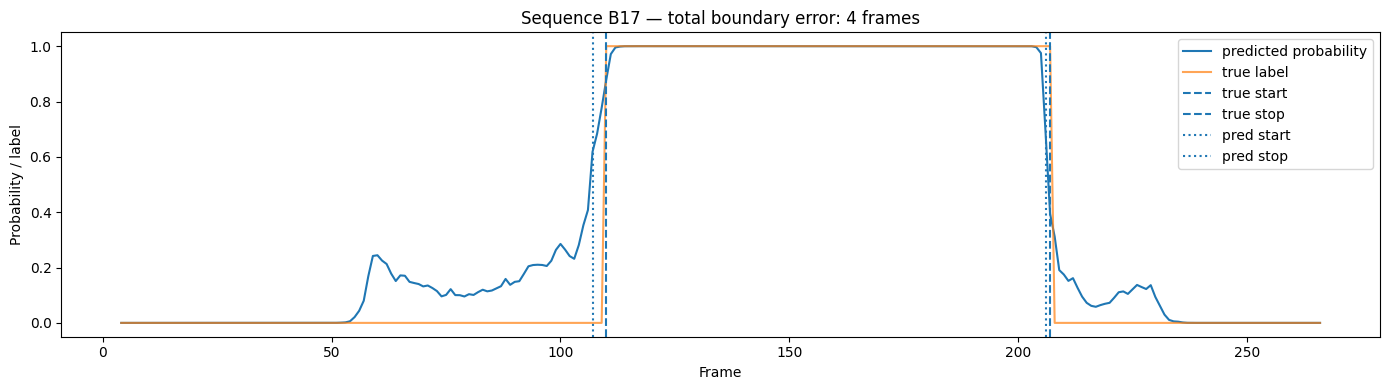

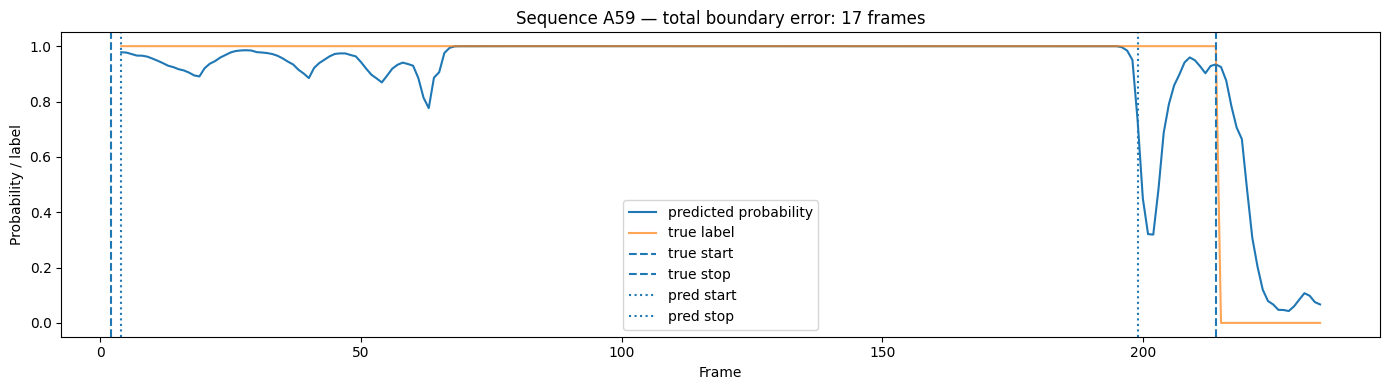

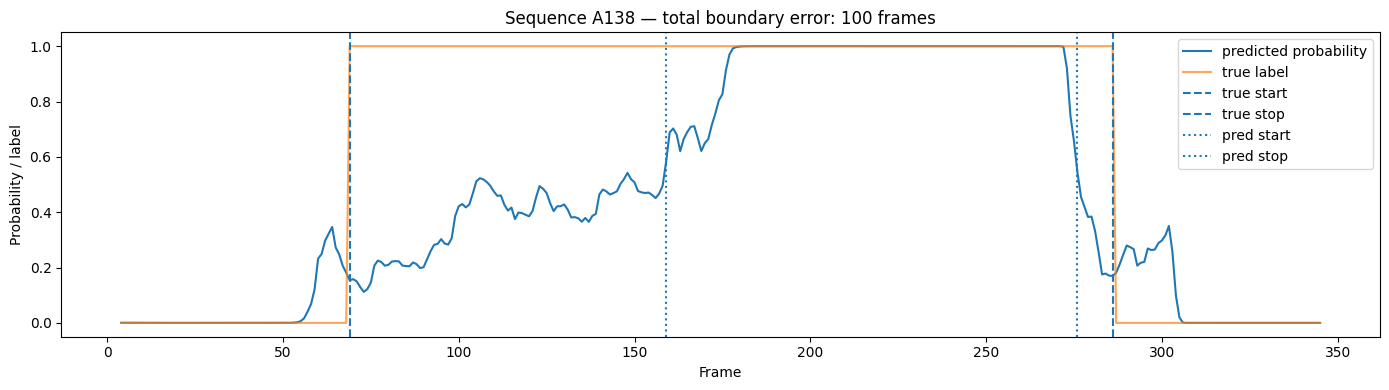

In [26]:
ranked_sequences = test_boundary_table.copy()

best_seq = ranked_sequences.sort_values("total_abs_error").iloc[0]["sequence_id"]
median_seq = ranked_sequences.sort_values("total_abs_error").iloc[len(ranked_sequences) // 2]["sequence_id"]
worst_seq = ranked_sequences.sort_values("total_abs_error", ascending=False).iloc[0]["sequence_id"]

for sequence_id in [best_seq, median_seq, worst_seq]:
    seq_df = test_pred_df[test_pred_df["sequence_id"] == sequence_id].copy()
    seq_df = seq_df.sort_values("frame_ref")

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop = int(seq_df["stop_frame"].iloc[0])
    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    plt.figure(figsize=(14, 4))
    plt.plot(seq_df["frame_ref"], seq_df["prob"], label="predicted probability")
    plt.plot(seq_df["frame_ref"], seq_df["label"], label="true label", alpha=0.7)

    plt.axvline(true_start, linestyle="--", label="true start")
    plt.axvline(true_stop, linestyle="--", label="true stop")

    if pred_start is not None:
        plt.axvline(pred_start, linestyle=":", label="pred start")
    if pred_stop is not None:
        plt.axvline(pred_stop, linestyle=":", label="pred stop")

    total_error = ranked_sequences.loc[
        ranked_sequences["sequence_id"] == sequence_id,
        "total_abs_error",
    ].iloc[0]

    plt.title(f"Sequence {sequence_id} — total boundary error: {total_error:.0f} frames")
    plt.xlabel("Frame")
    plt.ylabel("Probability / label")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [27]:
# Boundary predictions for all sequences: top 20 worst and best

X_all, y_all, meta_all = make_windows_for_all_sequences(
    all_df,
    feature_cols=BASE_COORD_FEATURES,
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

X_all = flatten_windows(X_all)
X_all_scaled = scaler.transform(X_all)

model.eval()

with torch.no_grad():
    all_logits = model(torch.tensor(X_all_scaled, dtype=torch.float32, device=DEVICE))
    all_probs = torch.sigmoid(all_logits).cpu().numpy()
    all_preds = (all_probs >= THRESHOLD).astype(int)

all_pred_df = meta_all.copy()
all_pred_df["prob"] = all_probs
all_pred_df["pred"] = all_preds
all_pred_df["label"] = y_all.astype(int)

all_boundary_table = build_boundary_table(all_pred_df)

worst_20_boundary_predictions = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

best_20_boundary_predictions = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=True)
    .head(20)
    .reset_index(drop=True)
)

print("Top 20 worst boundary predictions:")
display(worst_20_boundary_predictions)

print("Top 20 best boundary predictions:")
display(best_20_boundary_predictions)

Top 20 worst boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A138,69,286,159,276,90,-10,90,10,1,100
1,A58,1,227,72,209,71,-18,71,18,1,89
2,A134,0,115,4,198,4,83,4,83,1,87
3,A88,1,258,30,213,29,-45,29,45,1,74
4,A57,64,254,72,207,8,-47,8,47,1,55
5,B11,70,190,112,194,42,4,42,4,1,46
6,A90,34,214,40,174,6,-40,6,40,1,46
7,A4,56,219,75,196,19,-23,19,23,1,42
8,A131,0,129,4,164,4,35,4,35,1,39
9,A101,2,230,4,267,2,37,2,37,1,39


Top 20 best boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A45,44,192,44,192,0,0,0,0,1,0
1,B19,101,195,101,195,0,0,0,0,1,0
2,B6,157,262,158,262,1,0,1,0,1,1
3,A35,55,127,55,128,0,1,0,1,1,1
4,A38,40,87,39,87,-1,0,1,0,1,1
5,A39,43,100,43,101,0,1,0,1,1,1
6,A46,26,122,26,121,0,-1,0,1,1,1
7,A115,65,168,64,168,-1,0,1,0,1,1
8,A11,24,241,25,241,1,0,1,0,1,1
9,B13,153,239,153,238,0,-1,0,1,1,1


## Conclusion

The final notebook trains one MoveNet-based binary frame classifier for Problem B. The classifier separates frames inside the squat exercise from frames before or after the exercise.

The model uses raw MoveNet 2D coordinates from 13 joints and a temporal window of 9 frames, meaning that each prediction is based on both spatial information from the body pose and short-term temporal information from surrounding frames.

### Frame-level performance

On the independent test set, the model achieves a precision of approximately 0.93, a recall of approximately 0.87, a binary F1 score of approximately 0.90, and an accuracy of approximately 0.87.

This indicates strong classification performance. The high precision means that when the model predicts a frame as belonging to the squat exercise, it is usually correct. The slightly lower recall means that the model misses some true exercise frames. In other words, the model is slightly conservative: it avoids many false positives, but at the cost of missing some positive frames.

### Boundary detection performance

When converting frame-level predictions into exercise segments, the model detects an exercise segment in 100% of the test sequences, corresponding to 18 out of 18 sequences.

The boundary error analysis shows a mean absolute start error of approximately 19 frames and a median absolute start error of approximately 9.5 frames. For the stop boundary, the mean absolute stop error is approximately 10.6 frames and the median absolute stop error is approximately 10 frames.

This indicates that most predictions are reasonably accurate. However, the mean start error is higher than the median start error, which suggests that a few sequences contain large deviations that increase the average error.

### Analysis of worst-performing sequences

The 20 sequences with the highest total boundary error show large deviations. For example, sequence A86 has a start error of 92 frames and a stop error of 42 frames. Sequence A138 has a start error of 95 frames and a stop error of 11 frames. Sequence A121 has a start error of 73 frames and a stop error of 18 frames.

At first glance, these appear to be major model failures. However, after manually inspecting these sequences in the original videos, it was observed that the ground-truth start frames from the Kinect cut files are often inaccurate. In many of the worst cases, the model prediction visually aligns better with the actual start of the squat than the provided ground truth.

This pattern was consistent across several of the worst-performing sequences. The model frequently predicts the beginning of the actual movement, while the reference start frame is delayed or inconsistent. Therefore, some of the largest measured errors are likely caused by incorrect reference annotations rather than only by incorrect model predictions.

### Analysis of best-performing sequences

The best-performing sequences show near-perfect predictions. Several sequences have 0 frame error for both start and stop, and most of the top 20 best sequences have a total boundary error of 3 frames or less.

This demonstrates that when the ground-truth annotations are accurate and aligned with the actual movement, the model can detect exercise boundaries with very high precision.

### Dead ends and unsuccessful improvements

Several alternative approaches were tested during the work but did not lead to meaningful improvements.

One tested approach was to manually correct the true start and stop frames for the worst-performing Kinect cut files and then compare the evaluation results again. The expectation was that correcting these labels would clearly improve the measured boundary performance. However, this did not lead to a significant improvement in the overall results. Although some individual sequences became more reasonable after correction, the aggregated metrics did not change enough to clearly improve the final conclusion. This suggests that the evaluation is affected by more than only a few incorrect start and stop annotations.

Another dead end was assuming that simply changing the reference start and stop frames would improve the frame-level metrics such as precision, recall, and F1. This was not necessarily the case, because the model itself was not retrained in that comparison. Only the reference labels and boundary positions were changed. Therefore, the predicted probabilities stayed the same, and only the interpretation of the predictions changed. This made the comparison useful for understanding label quality, but it did not directly improve the trained classifier.

It was also considered whether the model should be retrained after manually correcting the worst sequences. However, because only a limited number of sequences were corrected, retraining on this partially modified dataset would not guarantee a fair or stable improvement. A larger and more systematic correction of the dataset would be needed before retraining could be expected to produce reliable improvements.

Another attempted direction was to interpret the largest boundary errors as pure model errors. Manual video inspection showed that this interpretation was too simple. In several cases, the model appeared to detect the actual movement start more accurately than the provided Kinect annotation. Therefore, treating every large error as a model failure would give a misleading picture of the classifier's performance.

### Interpretation

The results show that the model performs well on frame-level classification and reliably detects an exercise segment in every test sequence. Boundary prediction is generally accurate, but the measured boundary error is strongly influenced by the quality of the ground-truth labels.

The largest errors are often connected to inconsistent or incorrect reference annotations. This confirms the teacher’s note that the provided cut Kinect files may not be perfectly aligned and should be verified before being used as absolute ground truth.

### Optimum settings

The best-performing final configuration was the MoveNet-based dense binary frame classifier using raw 2D coordinates from 13 selected joints and a temporal window of 9 frames.

The final champion configuration used the following settings: a window size of 9 frames, raw coordinate features only, a dense neural network classifier, binary cross-entropy loss with positive class weighting, Adam optimization, early stopping based on validation loss, and the selected decision threshold from the validation experiments.

This configuration worked best because it produced the strongest balance between precision and recall on the validation/test evaluation. It achieved high precision, meaning that predicted exercise frames were usually correct, while maintaining sufficient recall to detect the exercise segment in all test sequences.

More complex feature engineering and post-hoc correction of only a few labels did not clearly improve the final results. Therefore, the final model was selected because it gave strong frame-level performance while still producing reliable segment-level boundary detection.
### Final conclusion

Overall, the classifier is effective for detecting squat exercise segments and could be used to automatically segment movement data. The frame-level results show strong classification performance, and the segment-level results show that the model successfully detects the exercise in all test sequences.

However, the evaluation of start and stop frames is limited by the quality of the ground-truth labels. Some of the largest measured errors are likely caused by incorrect or inconsistent Kinect annotations rather than by the model itself.

A clear improvement for future work would be to manually correct the dataset more systematically, especially the sequences with the largest boundary errors, and then retrain and re-evaluate the model using the improved annotations. The current results also show that the model itself can help identify suspicious labels, making it useful not only for classification but also for improving dataset quality.

# Extended web application (CSV download)

We have updated the web application to use the complete pipeline of Movenet 2D -> Kinect 3D. This was done by adding a new section in the "Pose Recorder" tab for listing all CSV files on the server, were one of the uploaded CSVs can be picked from the list and then downloaded as 3D Movenet or Kinect. A toggle button is also in place for chosing if the file should include none-squat frames or not.

!["None"](img/Csv_listing.png)

## Small fixes

- Camera button have been changed to be able to turning off after start it
- Camera recording model type changed from "SINGLEPOSE_LIGHTNING" to "SINGLEPOSE_THUNDER"
- Resolution resize overlay to video changed from 1280/720 -> 1920/1080

